# PathSnap — Model comparison and selection

Reads the results saved by the six model notebooks in `models/` and puts them side by side. All six were trained
and scored with the same code (`pathsnap_common.py`): same features, same GroupKFold(5)-by-trip folds on the 80
train trips, same metrics, and the same student_test evaluation. The nearest-road rule (always pick the closest
arc) is included as a reference point; it has no probabilities, so log loss is N/A.

**Primary selection metric: cross-validated observation-level top-1 accuracy** (with macro F1 and log loss as
tie-breakers). Top-1 is exactly the task: "which road segment is this fix on?". Log loss matters because the HMM
uses the probabilities. student_test is reported for every model but is a development check, not the selection
criterion.

In [1]:
import json, sys, time
sys.path.insert(0, "../model_training")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathsnap_common import *

MODELS = ["logistic_regression", "gaussian_nb", "knn", "random_forest", "hist_gradient_boosting", "mlp"]
R = {m: json.load(open(OUT_DIR / m / "results.json")) for m in MODELS}
CV = {m: pd.read_csv(OUT_DIR / m / "cv_folds.csv") for m in MODELS}
LABEL = {"logistic_regression": "Logistic Regression", "gaussian_nb": "Gaussian NB", "knn": "kNN (k=50)",
         "random_forest": "Random Forest", "hist_gradient_boosting": "Hist Gradient Boosting", "mlp": "MLP (64-32)"}
(OUT_DIR / "comparison").mkdir(parents=True, exist_ok=True)

## 1. Reference: nearest-road rule under the same folds

In [2]:
train = load_partition("train"); test = load_partition("student_test")
folds = make_folds(train)
base_cv = []
for k, vt in enumerate(folds):
    v = train[np.isin(train.tidx, vt)]
    res, _ = evaluate(v, -v.dist_rank.values.astype(float), "train", with_probs=False)
    base_cv.append(dict(fold=k + 1, val_top1=res["top1"], val_macro_f1=res["macro_f1"], val_continuity=res["continuity"]))
base_cv = pd.DataFrame(base_cv)
base_test, _ = evaluate(test, -test.dist_rank.values.astype(float), "student_test", with_probs=False)
base_cv.round(4)

,fold,val_top1,val_macro_f1,val_continuity
0,1,0.6268,0.3882,0.9346
1,2,0.5749,0.4147,0.9107
2,3,0.5526,0.3469,0.9316
3,4,0.5688,0.4054,0.9101
4,5,0.5093,0.3427,0.9464


## 2. Consolidated comparison table

In [3]:
def short_cfg(c):
    drop = {"preprocessing", "train_frac", "random_state", "priors", "criterion", "bootstrap", "max_depth", "loss",
            "early_stopping", "optimizer", "activation", "metric", "solver", "max_bins", "var_smoothing"}
    return ", ".join(f"{k}={v}" for k, v in c.items() if k not in drop) + f"; train_frac={c['train_frac']}"

rows = []
for m in MODELS:
    r, cv = R[m], CV[m]
    s = r["student_test"]
    rows.append({"Model": LABEL[m], "Family": r["family"], "Key configuration": short_cfg(r["config"]),
                 "CV Macro F1": f"{cv.val_macro_f1.mean():.4f} ± {cv.val_macro_f1.std():.4f}",
                 "CV Top-1": f"{cv.val_top1.mean():.4f} ± {cv.val_top1.std():.4f}",
                 "Test Top-1": round(s["top1"], 4), "Test Top-1 (all fixes)": round(s["top1_all"], 4),
                 "Route continuity": round(s["continuity"], 4), "Test Macro F1": round(s["macro_f1"], 4),
                 "Log Loss": round(s["logloss"], 4), "Precision": round(s["precision"], 4),
                 "Recall": round(s["recall"], 4), "F1": round(s["f1"], 4),
                 "Train time (s)": round(s["fit_s"], 1), "Inference (ms / 1k fixes)": round(s["predict_ms_per_1k_fixes"], 1)})
rows.append({"Model": "Nearest road (rule)", "Family": "Heuristic baseline", "Key configuration": "pick smallest dist",
             "CV Macro F1": f"{base_cv.val_macro_f1.mean():.4f} ± {base_cv.val_macro_f1.std():.4f}",
             "CV Top-1": f"{base_cv.val_top1.mean():.4f} ± {base_cv.val_top1.std():.4f}",
             "Test Top-1": round(base_test["top1"], 4), "Test Top-1 (all fixes)": round(base_test["top1_all"], 4),
             "Route continuity": round(base_test["continuity"], 4), "Test Macro F1": round(base_test["macro_f1"], 4),
             "Log Loss": "N/A (no probabilities)", "Precision": "N/A", "Recall": "N/A", "F1": "N/A",
             "Train time (s)": 0, "Inference (ms / 1k fixes)": "N/A"})
table = pd.DataFrame(rows)
table.to_csv(OUT_DIR / "comparison" / "comparison_table.csv", index=False)
pd.set_option("display.max_colwidth", 60)
table

,Model,Family,Key configuration,CV Macro F1,CV Top-1,Test Top-1,Test Top-1 (all fixes),Route continuity,Test Macro F1,Log Loss,Precision,Recall,F1,Train time (s),Inference (ms / 1k fixes)
0,Logistic Regression,Linear / probabilistic,"C=1.0, penalty=l2, max_iter=500; train_frac=0.4",0.7090 ± 0.0495,0.8620 ± 0.0308,0.8708,0.8368,0.9695,0.7229,0.0746,0.8485,0.845,0.8468,3.2,4.0
1,Gaussian NB,Probabilistic (generative),; train_frac=1.0,0.5559 ± 0.0257,0.7618 ± 0.0375,0.7820,0.7544,0.9667,0.5732,0.7279,0.4884,0.9135,0.6365,4.5,5.8
2,kNN (k=50),Instance-based,"n_neighbors=50, weights=distance; train_frac=0.05",0.6852 ± 0.0479,0.8507 ± 0.0281,0.8637,0.8336,0.9725,0.7026,0.0772,0.8655,0.8352,0.8501,0.1,5220.8
3,Random Forest,Ensemble (bagging),"n_estimators=200, max_features=sqrt, min_samples_leaf=20...",0.7418 ± 0.0536,0.8713 ± 0.0348,0.8869,0.8656,0.9748,0.7605,0.0541,0.9069,0.8565,0.881,106.9,93.0
4,Hist Gradient Boosting,Boosting,"max_iter=200, learning_rate=0.1, max_leaf_nodes=31, min_...",0.7353 ± 0.0612,0.8699 ± 0.0369,0.8864,0.8618,0.9691,0.7548,0.0637,0.8807,0.8821,0.8814,8.7,48.1
5,MLP (64-32),Neural network,"hidden_layer_sizes=[64, 32], alpha=0.0001, learning_rate...",0.7511 ± 0.0535,0.8724 ± 0.0351,0.8884,0.8513,0.9781,0.7721,0.0542,0.8898,0.8737,0.8817,170.2,14.7
6,Nearest road (rule),Heuristic baseline,pick smallest dist,0.3796 ± 0.0332,0.5665 ± 0.0424,0.5540,0.5413,0.9395,0.3761,N/A (no probabilities),N/A,N/A,N/A,0.0,N/A


## 3. Plots

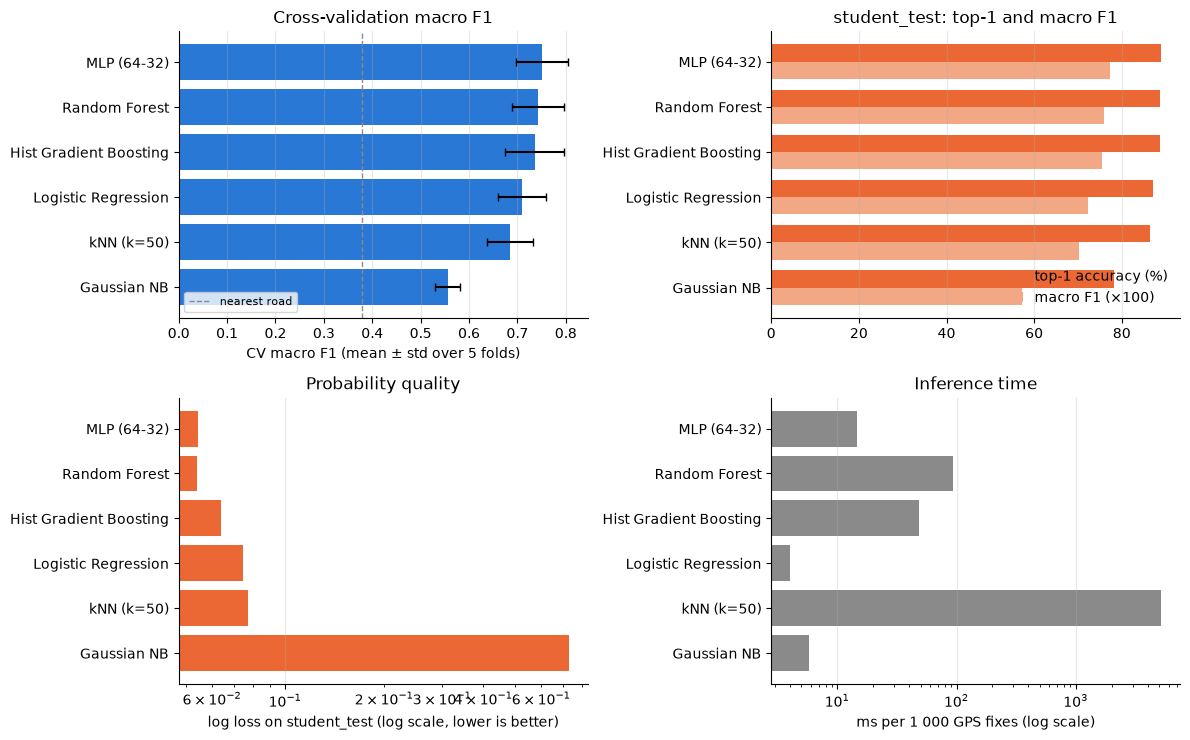

In [4]:
order = sorted(MODELS, key=lambda m: CV[m].val_top1.mean())
lab = [LABEL[m] for m in order]
fig, axs = plt.subplots(2, 2, figsize=(12, 7.5))
ax = axs[0, 0]
ax.barh(lab, [CV[m].val_macro_f1.mean() for m in order], xerr=[CV[m].val_macro_f1.std() for m in order],
        color=BLUE, capsize=3)
ax.axvline(base_cv.val_macro_f1.mean(), color=GREY, ls="--", lw=1, label="nearest road")
ax.set(xlabel="CV macro F1 (mean ± std over 5 folds)", title="Cross-validation macro F1"); ax.legend(frameon=True, loc="lower left", fontsize=8)
ax = axs[0, 1]
y = np.arange(len(order)); h = .38
ax.barh(y + h / 2, [R[m]["student_test"]["top1"] * 100 for m in order], h, color=ORANGE, label="top-1 accuracy (%)")
ax.barh(y - h / 2, [R[m]["student_test"]["macro_f1"] * 100 for m in order], h, color="#f2a785", label="macro F1 (×100)")
ax.set_yticks(y, lab); ax.set(title="student_test: top-1 and macro F1"); ax.legend(frameon=False, loc="lower right")
ax = axs[1, 0]
ax.barh(lab, [R[m]["student_test"]["logloss"] for m in order], color=ORANGE)
ax.set_xscale("log"); ax.set(xlabel="log loss on student_test (log scale, lower is better)", title="Probability quality")
ax = axs[1, 1]
ax.barh(lab, [R[m]["student_test"]["predict_ms_per_1k_fixes"] for m in order], color=GREY)
ax.set_xscale("log"); ax.set(xlabel="ms per 1 000 GPS fixes (log scale)", title="Inference time")
for a in axs.ravel():
    a.spines[["top", "right"]].set_visible(False); a.grid(axis="x", alpha=.3)
fig.tight_layout(); fig.savefig(OUT_DIR / "comparison" / "fig_comparison.png", dpi=150); plt.show()

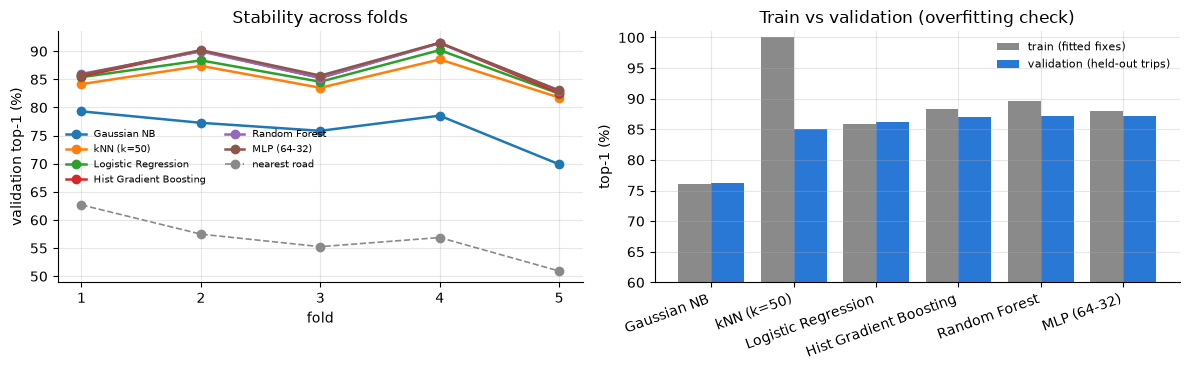

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for m in order:
    axs[0].plot(CV[m].fold, CV[m].val_top1 * 100, "o-", lw=1.8, label=LABEL[m])
axs[0].plot(base_cv.fold, base_cv.val_top1 * 100, "o--", color=GREY, lw=1.2, label="nearest road")
axs[0].set(xlabel="fold", ylabel="validation top-1 (%)", title="Stability across folds", xticks=[1, 2, 3, 4, 5])
axs[0].legend(frameon=False, fontsize=7, ncol=2)
x = np.arange(len(order))
axs[1].bar(x - .2, [CV[m].train_top1.mean() * 100 for m in order], .4, color=GREY, label="train (fitted fixes)")
axs[1].bar(x + .2, [CV[m].val_top1.mean() * 100 for m in order], .4, color=BLUE, label="validation (held-out trips)")
axs[1].set_xticks(x, lab, rotation=20, ha="right"); axs[1].set_ylim(60, 101)
axs[1].set(ylabel="top-1 (%)", title="Train vs validation (overfitting check)"); axs[1].legend(frameon=False, fontsize=8)
for a in axs:
    a.spines[["top", "right"]].set_visible(False); a.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT_DIR / "comparison" / "fig_stability_overfit.png", dpi=150); plt.show()

## 4. Paired comparison against the best model

The fold-to-fold spread (± 3 pp) mostly comes from *which trips* are in a fold, not from the model: every model
moves up and down together. Because all models use the same folds, the fair test is the **paired** difference per
fold: (model − best model) on the same 16 held-out trips.

In [6]:
best = order[-1]
paired = pd.DataFrame({LABEL[m]: (CV[m].val_top1.values - CV[best].val_top1.values) * 100 for m in order[::-1]},
                      index=[f"fold {k}" for k in range(1, 6)]).T
paired["mean (pp)"] = paired.mean(axis=1); paired["std (pp)"] = paired.iloc[:, :5].std(axis=1)
paired.to_csv(OUT_DIR / "comparison" / "paired_vs_best.csv")
print(f"top-1 difference to {LABEL[best]} per fold, percentage points")
paired.round(2)

top-1 difference to MLP (64-32) per fold, percentage points


,fold 1,fold 2,fold 3,fold 4,fold 5,mean (pp),std (pp)
MLP (64-32),0.00,0.00,0.00,0.00,0.00,0.00,0.00
Random Forest,0.16,-0.23,-0.40,-0.07,-0.03,-0.11,0.21
Hist Gradient Boosting,-0.26,-0.13,-0.41,-0.03,-0.46,-0.26,0.18
Logistic Regression,-0.42,-1.83,-1.10,-1.31,-0.57,-1.04,0.57
kNN (k=50),-1.66,-2.80,-2.17,-2.97,-1.25,-2.17,0.73
Gaussian NB,-6.50,-12.93,-9.82,-12.97,-13.12,-11.07,2.90


## 5. Selection

**Untuned ranking (CV top-1, paired against the best):** MLP 87.24%, random forest
-0.11 pp, HGB -0.26 pp, logistic regression
-1.04 pp, kNN -2.17 pp, Gaussian NB -11.07 pp.

- **Not selected:** Gaussian NB (independence / Gaussian assumptions are violated; log loss ~10× the others),
  kNN (lower accuracy and ~5.2 s per 1,000 fixes, too slow for the live demo),
  logistic regression (underfits; behind the MLP in every fold, by 0.4–1.8 pp).
- **The top three (MLP, random forest, HGB) are within 0.26 pp.** We picked **HGB as the model to tune** because
  (1) its iteration history shows the untuned settings are unstable (no L2 penalty; validation loss rises after
  ~40-60 trees), i.e. clear headroom from tuning; (2) it trains 12× faster than the random forest and
  20× faster than the MLP, which makes a 5-fold Bayesian search with ~30 trials affordable; (3) it is
  deterministic given the seed, has a small model file and optimises log loss directly (probabilities for the HMM).
- **Outcome** (`bayesian_optimisation.ipynb`): tuned HGB reaches CV top-1 87.58%, better than the
  untuned MLP in 5/5 folds (mean +0.33 pp), and has the best student_test top-1
  (89.30%), macro F1 (0.7808) and log loss (0.0526).
  **Tuned HGB is the final classifier** used by the HMM and exported to `results/final_model/`.
